# Unsupervised Learning for Text: Clustering and Topic Models

We look for structure in a collection of documents in two ways:

- **clustering** with k-means: every document goes into exactly one group;
- **topic models** (LDA, then NMF): every document is a mixture of topics, and every topic is a
  distribution over words.

The corpus is **20 newsgroups**, four categories. We do know the newsgroup of each post, but we keep
it aside: the models never see it, and we only use it at the end to check what they found.

In [1]:
# Run once if you are not using the course environment.
# %pip install -q numpy pandas scipy scikit-learn matplotlib plotly spacy gensim
# !python -m spacy download en_core_web_sm

---
## The data

Headers, signatures and quoted replies are removed, so that only what each author wrote is left.
The training posts are what we cluster and model; the test posts are used once, to evaluate a topic
model on documents it has never seen.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_20newsgroups

categories = ["comp.graphics", "rec.autos", "sci.space", "talk.politics.mideast"]
clean = ("headers", "footers", "quotes")

train = fetch_20newsgroups(subset="train", categories=categories, remove=clean)
test = fetch_20newsgroups(subset="test", categories=categories, remove=clean)
group_names = np.array(train.target_names)

print(f"{len(train.data)} training posts, {len(test.data)} test posts")

2335 training posts, 1555 test posts


### Lemmatization

Clustering and topic models describe groups of documents by their words, so we want *car* and *cars*,
or *launch* and *launched*, to count as the same word. A **lemmatizer** maps every word to its
dictionary form. We use spaCy, and in the same pass we keep only alphabetic tokens of three or more
letters that are not stopwords.

spaCy analyses every word in context, so this is the slowest cell of the notebook (about a minute).
The parser and the named entity recognizer are switched off, since we only need lemmas.

In [2]:
import time
import spacy

nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])

def lemmatize(texts):
    # one string per document: the lemmas of its content words, separated by spaces
    out = []
    for doc in nlp.pipe(texts, batch_size=64):
        out.append(" ".join(tok.lemma_.lower() for tok in doc
                            if tok.is_alpha and not tok.is_stop and len(tok) > 2))
    return out

start = time.time()
lemmas_train = lemmatize(train.data)
lemmas_test = lemmatize(test.data)
print(f"lemmatized {len(lemmas_train) + len(lemmas_test)} posts in {time.time() - start:.0f} seconds")

lemmatized 3890 posts in 72 seconds


In [3]:
print(train.data[3].strip()[:400])
print("-" * 40)
print(lemmas_train[3][:400])

Exactly. Some of the SPACE:1999 effects remain first-rate even today. 
 

Later on, the Andersons tried to shed their reputation as creators of some
of the worst pseudo-scientific shows in TV history by flying "Into Infinity."
This was a one-off thing done as part of BBC's "educational SF" series "The
Day After Tomorrow." The Anderson episode dealt with a spaceship capable of
reaching the speed of
----------------------------------------
exactly effect remain rate today later andersons try shed reputation creator bad pseudo scientific show history fly infinity thing bbc educational series day tomorrow anderson episode deal spaceship capable reach speed light lightship altare man crew eventually journey black hole end far galaxy think see year old like fan guess easily satisfied know infinity release video show vhs know thunderbird


### Short posts

Many posts are one or two lines (*"Thanks in advance!"*), and some are empty once the quoted reply is
gone. With a handful of words there is nothing to group or to describe, so we keep only posts with at
least 20 content words.

In [4]:
n_words = np.array([len(d.split()) for d in lemmas_train])
n_words_test = np.array([len(d.split()) for d in lemmas_test])

print(f"median length: {np.median(n_words):.0f} content words")
print(f"posts with fewer than 20: {(n_words < 20).mean():.0%}")

keep = n_words >= 20
docs = [d for d, k in zip(lemmas_train, keep) if k]
raw_docs = [d for d, k in zip(train.data, keep) if k]  # original text, only for display
y = train.target[keep]  # kept aside until we check the results

keep_test = n_words_test >= 20
docs_test = [d for d, k in zip(lemmas_test, keep_test) if k]

print(f"\nkept {len(docs)} training posts and {len(docs_test)} test posts")

median length: 33 content words
posts with fewer than 20: 31%

kept 1613 training posts and 1108 test posts


---
# Part 1: Clustering with k-means

## Documents as unit vectors

Each post becomes a TF-IDF vector. `TfidfVectorizer` also divides every vector by its length, so all
documents have norm 1. This matters for k-means, which measures **Euclidean** distance, while text
similarity is usually the **cosine**. For vectors of length 1 the two agree:

$$
\lVert \mathbf{a} - \mathbf{b} \rVert^2 = 2 - 2 \cos(\mathbf{a}, \mathbf{b})
$$

so the closest centroid in Euclidean distance is also the most similar one in cosine.

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(min_df=5, max_df=0.5)
X = tfidf.fit_transform(docs)
vocab = tfidf.get_feature_names_out()
print("documents x terms:", X.shape)

norms = np.sqrt(X.multiply(X).sum(axis=1)).A.ravel()
print(f"norms between {norms.min():.3f} and {norms.max():.3f}")

a, b = X[0].toarray().ravel(), X[1].toarray().ravel()
print(f"squared distance {np.sum((a - b) ** 2):.4f}   2 - 2 cos {2 - 2 * a @ b:.4f}")

documents x terms: (1613, 4517)
norms between 1.000 and 1.000
squared distance 1.9639   2 - 2 cos 1.9639


## k-means on the TF-IDF vectors

We ask for $K = 4$ clusters. Each cluster is described by its **centroid**.
A centroid is the average document of its cluster: a vector over the same vocabulary, where each weight is that word's mean TF-IDF across the cluster's posts. It's a synthetic document, not a real one, and that shows in three ways:

- It's dense. A real post uses a few dozen words. The centroid has a nonzero weight for every word used by any member, though most of those weights are tiny.
- It isn't unit length. Averaging unit vectors that point in different directions gives a shorter vector. Its squared length equals the average cosine similarity between all pairs of members (each post paired with itself included). So a tight cluster has a centroid close to length 1, and a loose one has a short centroid.
- Its largest weights are the words that are both common in the cluster and heavily weighted where they appear. That's why reading the top entries describes the cluster.

In [46]:
from sklearn.cluster import KMeans

def top_terms(centroid, n=10):
    return ", ".join(vocab[np.argsort(centroid)[-n:][::-1]])

km_full = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X)

for j, centroid in enumerate(km_full.cluster_centers_):
    print(f"cluster {j} ({np.sum(km_full.labels_ == j):4d} posts): {top_terms(centroid)}")

cluster 0 ( 189 posts): israel, israeli, jews, arab, arabs, state, jewish, attack, kill, israelis
cluster 1 ( 121 posts): armenian, armenians, turkish, turkey, people, greek, armenia, turks, say, genocide
cluster 2 (1003 posts): space, know, file, program, like, think, image, thank, use, need
cluster 3 ( 300 posts): car, drive, engine, dealer, good, price, buy, like, new, look


In [52]:
np.argsort(km_full.cluster_centers_[0])

array([2258, 2453, 2454, ..., 2195, 2172, 2171], shape=(4517,))

In [47]:
vocab

array(['abandon', 'abide', 'ability', ..., 'zionists', 'zone', 'zoom'],
      shape=(4517,), dtype=object)

Now we look at the newsgroups, for the first time:

In [13]:
pd.crosstab(km_full.labels_, group_names[y], rownames=["cluster"], colnames=["newsgroup"])

newsgroup,comp.graphics,rec.autos,sci.space,talk.politics.mideast
cluster,,,,
0,0,0,0,189
1,0,0,0,121
2,371,84,427,121
3,0,298,1,1


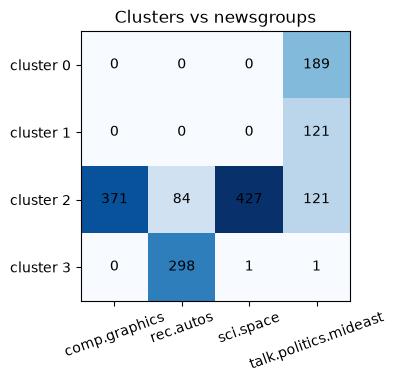

In [14]:
table = pd.crosstab(km_full.labels_, group_names[y], rownames=["cluster"], colnames=["newsgroup"])

plt.figure(figsize=(6, 3.5))
plt.imshow(table.values, cmap="Blues")
plt.xticks(range(4), table.columns, rotation=20)
plt.yticks(range(4), [f"cluster {j}" for j in table.index])
for i in range(4):
    for j in range(4):
        plt.text(j, i, table.values[i, j], ha="center", va="center")
plt.title("Clusters vs newsgroups")
plt.show()

Two small, clean clusters about the Middle East, one about cars, and one huge cluster where graphics,
space and everything else end up together. Why?

### Distances in thousands of dimensions

Two posts share very few of the thousands of words in the vocabulary, so most pairs of documents are
almost orthogonal: their cosine similarity is close to 0, whatever their topic. When almost every
document is equally far from every other, the "nearest centroid" is decided by small differences.

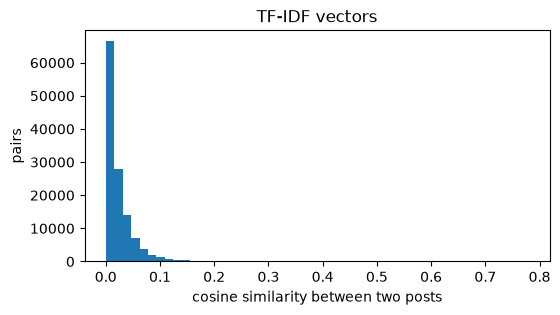

pairs with similarity below 0.05: 88%


In [15]:
rng = np.random.default_rng(0)
sample = rng.choice(X.shape[0], 500, replace=False)

sims = (X[sample] @ X[sample].T).toarray()[np.triu_indices(500, k=1)]

plt.figure(figsize=(6, 3))
plt.hist(sims, bins=50)
plt.xlabel("cosine similarity between two posts")
plt.ylabel("pairs")
plt.title("TF-IDF vectors")
plt.show()

print(f"pairs with similarity below 0.05: {(sims < 0.05).mean():.0%}")

## Reducing the dimensions first

**Truncated SVD** (also called **Latent Semantic Analysis** on text) compresses the vocabulary into a
few dimensions that capture the words which tend to occur together. It is the version of **PCA** used
for sparse matrices: PCA first subtracts the mean of every column, which would turn our sparse
matrix into a dense one, and truncated SVD skips that step.

We keep 20 dimensions and normalize again, so that Euclidean distance and cosine still agree.

documents x dimensions: (1613, 20)
share of the variance kept: 9%


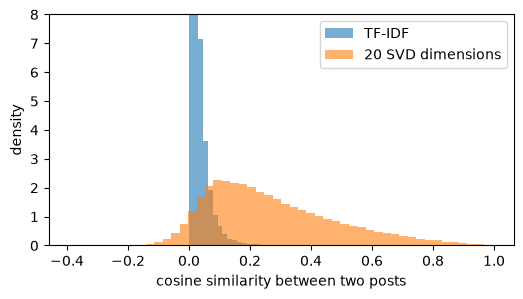

In [16]:
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer

svd = TruncatedSVD(n_components=20, random_state=0)
Z = Normalizer().fit_transform(svd.fit_transform(X))
print("documents x dimensions:", Z.shape)
print(f"share of the variance kept: {svd.explained_variance_ratio_.sum():.0%}")

sims_z = (Z[sample] @ Z[sample].T)[np.triu_indices(500, k=1)]

plt.figure(figsize=(6, 3))
plt.hist(sims, bins=50, alpha=0.6, density=True, label="TF-IDF")
plt.hist(sims_z, bins=50, alpha=0.6, density=True, label="20 SVD dimensions")
plt.xlabel("cosine similarity between two posts")
plt.ylabel("density")
plt.ylim(0, 8)
plt.legend()
plt.show()

In the reduced space similarities are spread out: some pairs are clearly close, others clearly far.
We run k-means again, on `Z`. To describe the clusters we still use words: the mean TF-IDF vector of
the posts in each cluster.

In [17]:
km = KMeans(n_clusters=4, n_init=10, random_state=0).fit(Z)
labels = km.labels_

for j in range(4):
    centroid = np.asarray(X[labels == j].mean(axis=0)).ravel()
    print(f"cluster {j} ({np.sum(labels == j):4d} posts): {top_terms(centroid)}")

cluster 0 ( 332 posts): car, drive, engine, good, dealer, buy, like, new, price, look
cluster 1 ( 456 posts): file, image, program, thank, graphic, software, know, color, format, use
cluster 2 ( 439 posts): israel, people, israeli, jews, armenian, armenians, kill, turkish, arab, say
cluster 3 ( 386 posts): space, launch, orbit, nasa, moon, think, like, year, earth, lunar


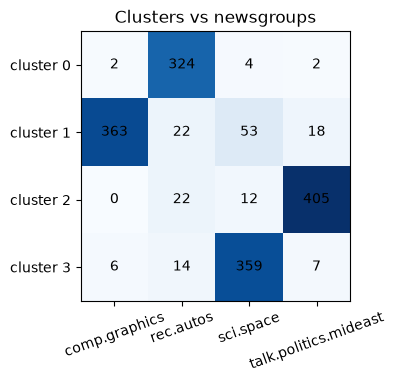

In [18]:
table = pd.crosstab(labels, group_names[y], rownames=["cluster"], colnames=["newsgroup"])

plt.figure(figsize=(6, 3.5))
plt.imshow(table.values, cmap="Blues")
plt.xticks(range(4), table.columns, rotation=20)
plt.yticks(range(4), [f"cluster {j}" for j in table.index])
for i in range(4):
    for j in range(4):
        plt.text(j, i, table.values[i, j], ha="center", va="center")
plt.title("Clusters vs newsgroups")
plt.show()

Each cluster now matches one newsgroup, with a few posts in the wrong place. Nobody told k-means
what the newsgroups were: the four groups come from the words alone.

## Seeing the clusters

To draw the posts we need 2 dimensions. Two common choices:

- **PCA** projects the 20 dimensions onto the 2 directions with the largest variance. It is linear,
  and distances on the plot are faithful on a large scale.
- **t-SNE** places the points so that **neighbours stay neighbours**. Groups come out well
  separated, but the distances *between* groups and the size of each group mean nothing.

The plots are interactive: hover on a point to read the post, click on the legend to hide a cluster.
Colour is the cluster, the marker is the true newsgroup.

In [54]:
import plotly.express as px
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

points = pd.DataFrame({
    "cluster": [f"cluster {j}" for j in labels],
    "newsgroup": group_names[y],
    "post": [d.strip()[:150].replace("\n", " ") + "..." for d in raw_docs],
})
order = {"cluster": [f"cluster {j}" for j in range(4)]}

pca_2d = PCA(n_components=2, random_state=0).fit_transform(Z)
points["pca 1"], points["pca 2"] = pca_2d[:, 0], pca_2d[:, 1]

fig = px.scatter(points, x="pca 1", y="pca 2", color="cluster", symbol="newsgroup",
                 hover_data={"post": True, "pca 1": False, "pca 2": False},
                 category_orders=order, opacity=0.7, title="PCA", width=850, height=550)
fig.update_traces(marker_size=5)
fig.show()

In [20]:
tsne_2d = TSNE(n_components=2, init="pca", random_state=0).fit_transform(Z)
points["tsne 1"], points["tsne 2"] = tsne_2d[:, 0], tsne_2d[:, 1]

fig = px.scatter(points, x="tsne 1", y="tsne 2", color="cluster", symbol="newsgroup",
                 hover_data={"post": True, "tsne 1": False, "tsne 2": False},
                 category_orders=order, opacity=0.7, title="t-SNE", width=850, height=550)
fig.update_traces(marker_size=5)
fig.show()

PCA keeps only two of the 20 directions, so the clusters overlap on the plot even where they are
separated in 20 dimensions. t-SNE shows four groups, plus the posts that sit between them: hover on
those, they are often short, or about two things at once. It also shows smaller groups *inside* some
clusters: hover to find out what the pieces of the Middle East cluster are about.

## What each cluster is about

The top terms of each cluster, with their weight in the mean TF-IDF vector:

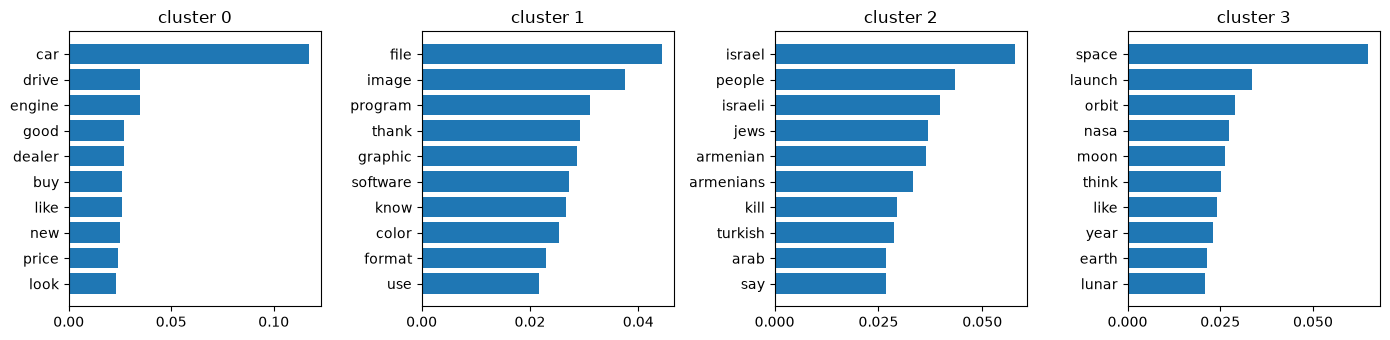

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for j, ax in enumerate(axes):
    centroid = np.asarray(X[labels == j].mean(axis=0)).ravel()
    top = np.argsort(centroid)[-10:]
    ax.barh(vocab[top], centroid[top])
    ax.set_title(f"cluster {j}")
    ax.xaxis.set_major_locator(plt.MaxNLocator(3))
plt.tight_layout()
plt.show()

## Choosing $K$

We used $K = 4$ because we knew there were four newsgroups. Without labels, two common checks:

- the **elbow**: the sum of squared distances of every post to its centroid (SSE, called `inertia_`
  in scikit-learn) always decreases as $K$ grows; we look for the point where it stops decreasing
  quickly;
- the **silhouette score**: for each post, is it closer to its own cluster than to the nearest other
  one? It goes from $-1$ (probably in the wrong cluster) to $1$ (well placed), and we average it over
  all posts.

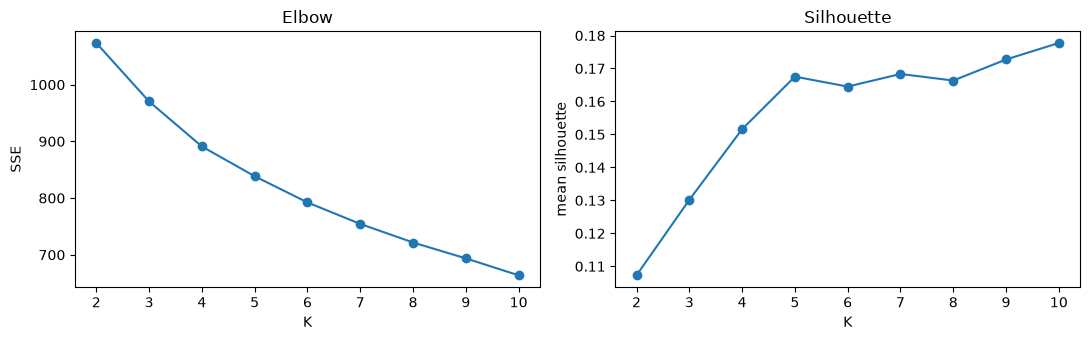

In [22]:
from sklearn.metrics import silhouette_score

ks = range(2, 11)
sse, silhouette = [], []
for k in ks:
    model = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Z)
    sse.append(model.inertia_)
    silhouette.append(silhouette_score(Z, model.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
ax1.plot(ks, sse, "o-")
ax1.set_xlabel("K")
ax1.set_ylabel("SSE")
ax1.set_title("Elbow")
ax2.plot(ks, silhouette, "o-")
ax2.set_xlabel("K")
ax2.set_ylabel("mean silhouette")
ax2.set_title("Silhouette")
plt.tight_layout()
plt.show()

On real text neither curve gives a sharp answer. The SSE bends only gently, and the silhouette rises
until $K = 5$ and then stays almost flat, because extra clusters split large groups into smaller,
tighter ones.
These curves narrow down the range; the final choice comes from **reading the clusters**.

The silhouette of every single post, grouped by cluster, shows more than the average:

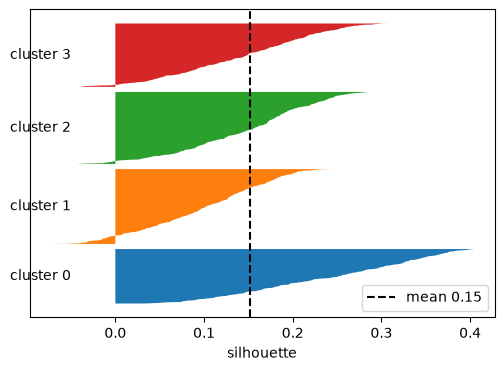

In [23]:
from sklearn.metrics import silhouette_samples

s = silhouette_samples(Z, labels)

plt.figure(figsize=(6, 4))
bottom = 0
for j in range(4):
    values = np.sort(s[labels == j])
    plt.fill_betweenx(np.arange(bottom, bottom + len(values)), 0, values)
    plt.text(-0.05, bottom + len(values) / 2, f"cluster {j}", ha="right", va="center")
    bottom += len(values) + 30
plt.axvline(s.mean(), color="black", linestyle="--", label=f"mean {s.mean():.2f}")
plt.xlabel("silhouette")
plt.yticks([])
plt.legend()
plt.show()

Every cluster has a body of well-placed posts and a small tail below 0: posts that would fit better
in another cluster. They are the same posts that sit between the groups in the t-SNE plot.

## Why normalize?

What if we skip the normalization, and cluster the raw TF-IDF vectors?

In [27]:
X_raw = TfidfVectorizer(min_df=5, max_df=0.5, norm=None).fit_transform(docs)
km_raw = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X_raw)

lengths = np.array([len(d.split()) for d in docs])
pd.DataFrame({"cluster": km_raw.labels_, "length": lengths}).groupby("cluster")["length"].describe()[
    ["count", "50%", "max"]].rename(columns={"50%": "median length"})

,count,median length,max
cluster,,,
0,1607.0,51.0,4441.0
1,1.0,4477.0,4477.0
2,1.0,3146.0,3146.0
3,4.0,3122.5,3921.0


Without normalization a long post is a long vector, far from everything else. k-means spends its
clusters on a few very long posts and puts nearly all the others in one cluster: it groups by
**length**, not by topic.

---
# Part 2: Topic models

Clustering gave every post exactly one group. A topic model describes every post as a **mixture** of
topics, and every topic as a **distribution over words**.

## Topics as terms

The simplest idea: a topic is a single word. Pick the $k$ words with the highest total TF-IDF in the
collection, then measure how much a post covers each topic by counting those words in it.

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

counts = CountVectorizer(min_df=5, max_df=0.5)
C = counts.fit_transform(docs)  # raw counts: documents x terms
words = counts.get_feature_names_out()

columns = np.argsort(np.asarray(X.sum(axis=0)).ravel())[-8:][::-1]
topical_terms = vocab[columns]
print("topical terms:", ", ".join(topical_terms))

term_counts = C[:, columns].toarray()
print(f"posts that contain none of them: {(term_counts.sum(axis=1) == 0).mean():.0%}")

topical terms: car, know, like, think, people, space, israel, time
posts that contain none of them: 20%


In [30]:
coverage = term_counts / np.maximum(term_counts.sum(axis=1, keepdims=True), 1)
pd.DataFrame(coverage[:5], columns=topical_terms).round(2)

,car,know,like,think,people,space,israel,time
0,0.00,0.17,0.17,0.00,0.17,0.0,0.25,0.25
1,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00
2,0.00,0.50,0.25,0.25,0.00,0.0,0.00,0.00
3,0.33,0.00,0.00,0.33,0.00,0.0,0.00,0.33
4,0.25,0.00,0.25,0.25,0.00,0.0,0.00,0.25


Two problems at once. The terms with the highest weight are mostly generic (*know*, *like*, *think*),
not topics. And a post about a launch that never uses the word *space* has no space coverage at all:
the other words of the post are ignored.

## LDA: topics as word distributions

Latent Dirichlet Allocation imagines that each word of a post was produced in two steps: pick a
topic according to the post's mixture, then pick a word from that topic. It learns both from the
collection:

- for every topic $j$, a distribution over words, $P(w \mid \theta_j)$;
- for every document $d$, its mixture of topics, $\boldsymbol{\pi}_d$.

LDA models how many times each word occurs, so it takes **counts**, not TF-IDF weights. Stopwords
were already removed during lemmatization. We start with $k = 4$ topics.

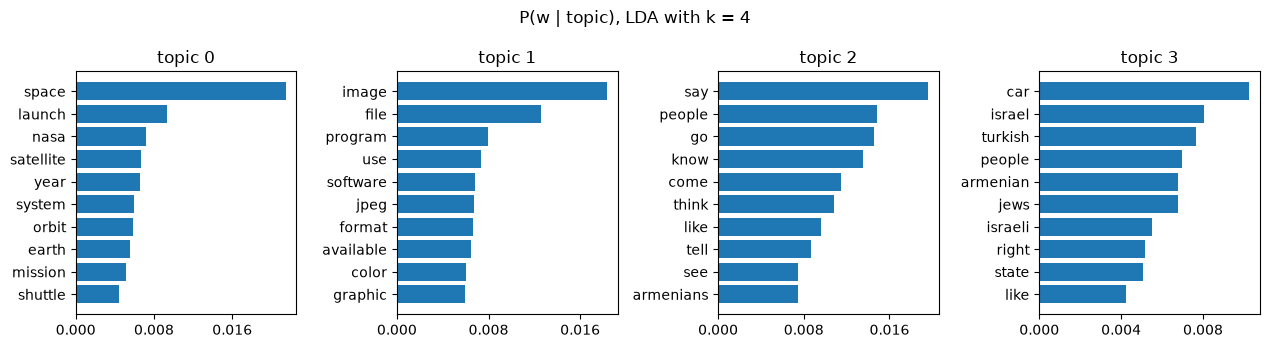

In [82]:
from sklearn.decomposition import LatentDirichletAllocation

lda = LatentDirichletAllocation(n_components=4, learning_method="batch", max_iter=20, random_state=0)
lda.fit(C)

# components_ holds unnormalized weights: dividing each row by its sum gives P(w | topic)
topic_word = lda.components_ / lda.components_.sum(axis=1, keepdims=True)

def plot_topics(topic_word, words, n=10, title=""):
    k = len(topic_word)
    fig, axes = plt.subplots(1, k, figsize=(3.2 * k, 3.5))
    for j, ax in enumerate(axes):
        top = np.argsort(topic_word[j])[-n:]
        ax.barh(words[top], topic_word[j][top])
        ax.set_title(f"topic {j}")
        ax.xaxis.set_major_locator(plt.MaxNLocator(3))
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_topics(topic_word, words, title="P(w | topic), LDA with k = 4")

The topics follow the words, not the newsgroups. Space and graphics come out clean. The cars and the
Middle East share a topic, and one topic collects the words of conversation (*say*, *people*, *go*,
*know*, *think*), which appear in every newsgroup: a topic of common words, not of a subject.

## Documents as mixtures

`transform` returns the mixture $\boldsymbol{\pi}_d$ of every post: one row per post, one column per
topic, each row summing to 1.

documents x topics: (1613, 4)


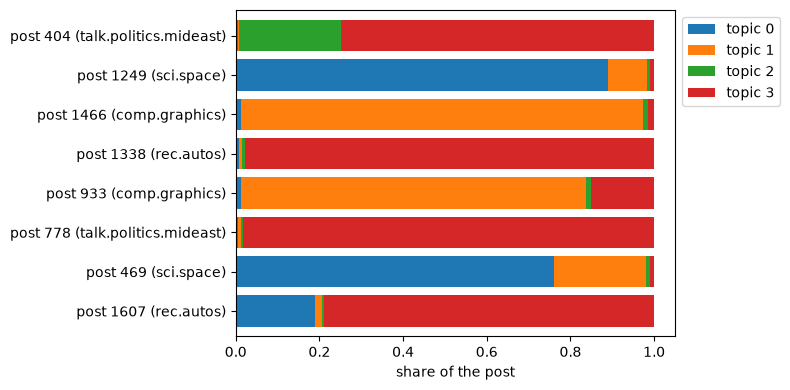

In [78]:
doc_topic = lda.transform(C)
print("documents x topics:", doc_topic.shape)

shown = rng.choice(len(docs), 8, replace=False)
mix = pd.DataFrame(doc_topic[shown], columns=[f"topic {j}" for j in range(4)],
                   index=[f"post {i} ({group_names[y[i]]})" for i in shown])

mix.plot.barh(stacked=True, figsize=(8, 4), width=0.8)
plt.xlabel("share of the post")
plt.legend(bbox_to_anchor=(1, 1))
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Some posts are almost entirely one topic, others are split. If a single label is needed, we take the
dominant topic, the largest entry of $\boldsymbol{\pi}_d$, and can compare it with the newsgroups as
we did for the clusters:

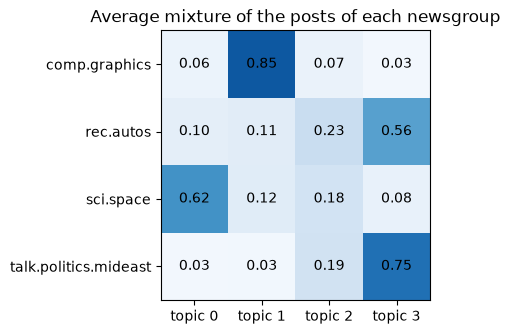

newsgroup,comp.graphics,rec.autos,sci.space,talk.politics.mideast
dominant topic,,,,
0,12,17,322,5
1,351,22,43,4
2,6,77,47,59
3,2,266,16,364


In [79]:
avg = pd.DataFrame(doc_topic, columns=[f"topic {j}" for j in range(4)]).groupby(group_names[y]).mean()

plt.figure(figsize=(6, 3.5))
plt.imshow(avg.values, cmap="Blues", vmin=0, vmax=1)
plt.xticks(range(4), avg.columns)
plt.yticks(range(4), avg.index)
for i in range(4):
    for j in range(4):
        plt.text(j, i, f"{avg.values[i, j]:.2f}", ha="center", va="center")
plt.title("Average mixture of the posts of each newsgroup")
plt.show()

pd.crosstab(doc_topic.argmax(axis=1), group_names[y], rownames=["dominant topic"], colnames=["newsgroup"])

### A new document

The topics are fixed after training, so LDA can give a mixture to a post it has never seen. The new
text goes through the same lemmatization and the same vocabulary:

In [80]:
new_posts = [
    "The engine of my car overheated on the way to the launch pad.",
    "Which file format should I use to save a JPEG image with more colors?",
]
new_counts = counts.transform(lemmatize(new_posts))
pd.DataFrame(lda.transform(new_counts), columns=[f"topic {j}" for j in range(4)], index=new_posts).round(2)

,topic 0,topic 1,topic 2,topic 3
The engine of my car overheated on the way to the launch pad.,0.54,0.04,0.04,0.37
Which file format should I use to save a JPEG image with more colors?,0.03,0.91,0.03,0.03


The first sentence is split between the space topic and the topic that contains *car*; the second is
almost entirely graphics. A clustering of the same sentences could only pick one group for each.

### Shared words

A word can have weight in more than one topic. The words whose probability is highest in their
*second* topic:

In [81]:
second_best = np.sort(topic_word, axis=0)[-2]
shared = np.argsort(second_best)[-10:][::-1]
pd.DataFrame(topic_word[:, shared].T, index=words[shared],
             columns=[f"topic {j}" for j in range(4)]).round(4)

,topic 0,topic 1,topic 2,topic 3
people,0.0004,0.0012,0.0148,0.0070
system,0.0060,0.0059,0.0000,0.0009
armenian,0.0000,0.0000,0.0054,0.0068
know,0.0016,0.0051,0.0135,0.0028
year,0.0066,0.0004,0.0045,0.0038
like,0.0020,0.0041,0.0096,0.0042
time,0.0042,0.0032,0.0073,0.0032
look,0.0015,0.0041,0.0057,0.0014
right,0.0004,0.0009,0.0041,0.0052
program,0.0040,0.0080,0.0000,0.0001


---
## Gensim alongside scikit-learn

**Gensim** is a library built for topic models. It represents a corpus as a list of documents, each a
list of `(word id, count)` pairs, and a `Dictionary` that maps ids to words. It does not need its own
preprocessing: `Sparse2Corpus` reads the count matrix we already built with scikit-learn.

In [85]:
from gensim.corpora import Dictionary
from gensim.matutils import Sparse2Corpus
from gensim.models import LdaModel, CoherenceModel

corpus = Sparse2Corpus(C, documents_columns=False)  # scikit-learn: one row per document
id2word = dict(enumerate(words))

print("first post, first pairs:", list(corpus[0])[:5])

g_lda = LdaModel(corpus, num_topics=4, id2word=id2word, passes=10, random_state=0)
for j in range(4):
    print(f"topic {j}:", ", ".join(w for w, _ in g_lda.show_topic(j, 8)))

first post, first pairs: [(np.int32(4074), np.int64(2)), (np.int32(598), np.int64(1)), (np.int32(2173), np.int64(4)), (np.int32(2355), np.int64(2)), (np.int32(4348), np.int64(1))]
topic 0: space, image, system, file, launch, program, nasa, use
topic 1: image, israel, israeli, point, right, know, question, problem
topic 2: say, people, go, know, come, think, like, tell
topic 3: car, armenian, like, jews, people, year, israel, new


Same data, same $k$, different topics: Gensim estimates LDA with a different algorithm and different
defaults, and LDA has no single right answer. Which set of topics is better? That is the question of
the next section.

## Evaluating topic models

There are no labels to compare with. Two common measures:

- **Perplexity** on held-out documents: LDA is a language model, so we can ask how surprised it is
  by posts it has not seen. Lower is better.
- **Topic coherence**: do the top words of a topic tend to occur in the same documents? Gensim's
  `CoherenceModel` computes it for any list of topics, including the ones found by scikit-learn.
  Higher is better.

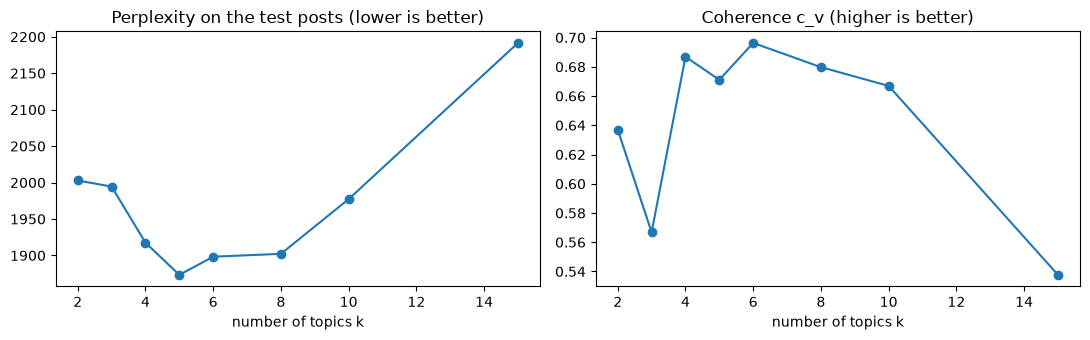

Gensim's LDA, k = 4: coherence 0.482
scikit-learn's LDA, k = 4: coherence 0.687


In [43]:
texts = [d.split() for d in docs]          # Gensim's coherence reads the tokenized documents
dictionary = Dictionary(texts)
C_test = counts.transform(docs_test)

def top_words(model, n=10):
    return [[words[i] for i in np.argsort(row)[-n:][::-1]] for row in model.components_]

def coherence(topics):
    return CoherenceModel(topics=topics, texts=texts, dictionary=dictionary,
                          coherence="c_v", processes=1).get_coherence()

topic_counts = [2, 3, 4, 5, 6, 8, 10, 15]
perplexity, coh = [], []
for k in topic_counts:
    model = LatentDirichletAllocation(n_components=k, learning_method="batch", max_iter=20,
                                      random_state=0).fit(C)
    perplexity.append(model.perplexity(C_test))
    coh.append(coherence(top_words(model)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
ax1.plot(topic_counts, perplexity, "o-")
ax1.set_xlabel("number of topics k")
ax1.set_title("Perplexity on the test posts (lower is better)")
ax2.plot(topic_counts, coh, "o-")
ax2.set_xlabel("number of topics k")
ax2.set_title("Coherence c_v (higher is better)")
plt.tight_layout()
plt.show()

print(f"Gensim's LDA, k = 4: coherence {coherence([[w for w, _ in g_lda.show_topic(j, 10)] for j in range(4)]):.3f}")
print(f"scikit-learn's LDA, k = 4: coherence {coherence(top_words(lda)):.3f}")

In [88]:
docs_test

['okay earth magnetic field miss okay object earth magnetic field produce electricty question use electricity power space low earth orbit vehicle fyou use magnetic field earth power idea dragless satellite create electrical field dragless satellite wrong suspend pilon pilon compensate drag think know want sure dragless satellite sound interestingly liek generator michael adams high jack',
 'main reason nation like russia observe satellite launch forb system whick loft nuclear bomb orbit plan detonate leo cause emp pulse interfere target command control system',
 'cook late exploration privately fund joseph banks resolution early endeavour colnett voyage galapagos substantially privately fund owner british whale vessel chancellor willoughby privately fund london merchant company voyage muscovy list endless funding eighty percent motivate potential profit percent potential glory percent desire advance sum human knowledge',
 'dealership today look buy car salesman show call buy car fleet 

Perplexity is lowest at $k = 5$ and coherence highest at $k = 6$: both prefer a few more topics than
four. The two LDA implementations also differ: at $k = 4$, Gensim's topics are clearly less coherent
than scikit-learn's. Let us look at $k = 6$:

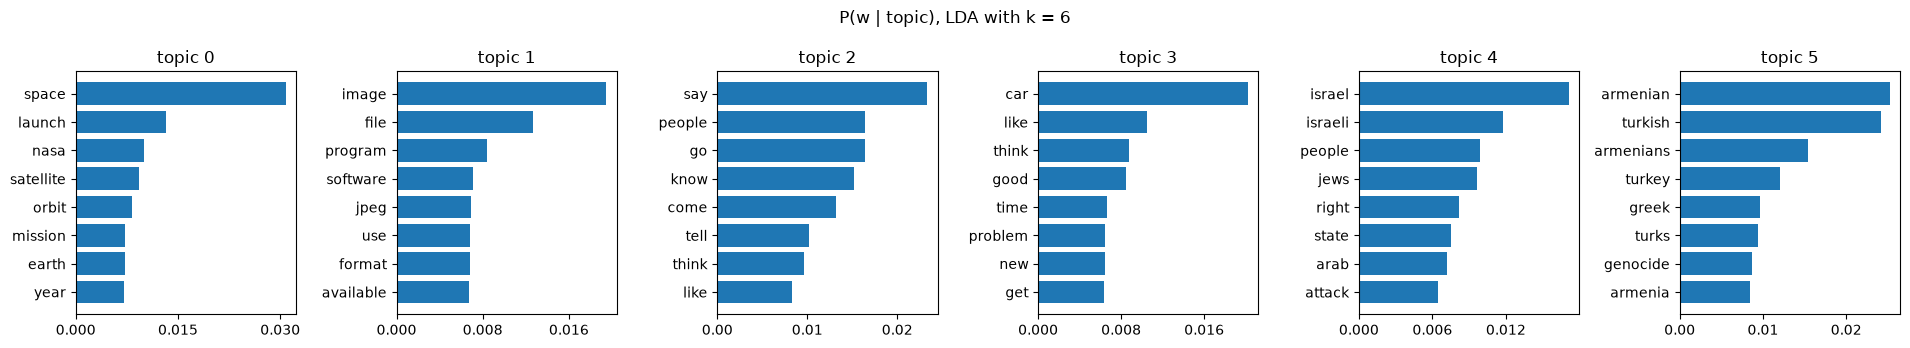

In [44]:
lda6 = LatentDirichletAllocation(n_components=6, learning_method="batch", max_iter=20, random_state=0).fit(C)
topic_word6 = lda6.components_ / lda6.components_.sum(axis=1, keepdims=True)
plot_topics(topic_word6, words, n=8, title="P(w | topic), LDA with k = 6")

With six topics the Middle East splits in two (Israel, and Armenia and Turkey), cars get a topic of
their own, and the topic of conversation words stays. The newsgroups are a human choice; the topics
are what the words support.

---
## NMF

**Non-negative matrix factorization** approximates the TF-IDF matrix as the product of a
documents $\times$ topics matrix and a topics $\times$ terms matrix, with no negative entries. It is
not a probabilistic model, but its output reads the same way: each topic is a weighted list of words,
each document a weighted combination of topics.

In [45]:
from sklearn.decomposition import NMF

nmf = NMF(n_components=6, init="nndsvda", max_iter=500, random_state=0).fit(X)
for j, row in enumerate(nmf.components_):
    print(f"topic {j}:", top_terms(row, 8))

print(f"\ncoherence: NMF {coherence([[vocab[i] for i in np.argsort(r)[-10:][::-1]] for r in nmf.components_]):.3f}"
      f", LDA {coherence(top_words(lda6)):.3f}")

topic 0: think, say, people, know, like, go, thing, come
topic 1: armenian, armenians, turkish, genocide, armenia, turkey, turks, people
topic 2: car, drive, engine, dealer, buy, price, new, good
topic 3: israel, israeli, jews, arab, attack, state, lebanese, arabs
topic 4: space, launch, nasa, orbit, satellite, shuttle, lunar, moon
topic 5: file, image, program, format, color, graphic, thank, convert

coherence: NMF 0.728, LDA 0.696


The six topics match LDA's one by one, the topic of conversation words included: both methods see
the same co-occurrences, through a different model.

---
## Exercises

- **Hierarchical clustering.** Take 40 posts, cluster them with `scipy.cluster.hierarchy.linkage` on
  the reduced vectors `Z`, and draw the `dendrogram` with the newsgroup of each post as its label.
  Compare `method="single"`, `"complete"` and `"average"`. Where would you cut the tree?
- **DBSCAN.** Run `sklearn.cluster.DBSCAN(metric="cosine")` on `X`, then on `Z`, for a few values of
  `eps`. How many posts end up as noise (label `-1`)? Why is density hard to use in thousands of
  dimensions?
- **How many dimensions?** Repeat the k-means on `Z` with 5, 50 and 200 SVD dimensions. How do the
  crosstab with the newsgroups and the silhouette change?
- **Lemmatization.** Build `X` from the original posts instead of the lemmas
  (`TfidfVectorizer(stop_words="english", min_df=5, max_df=0.5)`). Do the top terms of the clusters
  and of the topics get better or worse?
- **The topic of conversation words.** Add *say*, *people*, *go*, *know*, *think* and a few more to a
  custom stopword list and refit LDA with $k = 4$. What happens to the topics? Is this a good idea in
  general?
- **LDA on TF-IDF.** Fit LDA on `X` instead of `C`. The code runs: why is it still a mistake?
- **Word intrusion.** For each topic of `lda6`, write down its 5 top words and add one top word of
  another topic, shuffled. Ask a classmate to spot the intruder. Which topics are easiest?